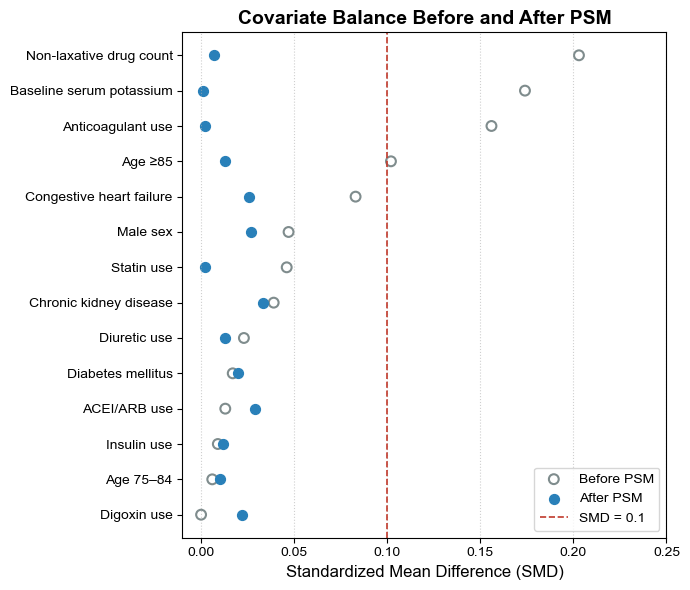

✅ Figure S1 生成完毕！


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

# 设置 Arial 字体
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

# 1. 直接读取你提供的数据
data = {
    'Variable': ['gender_male', 'age_75_84', 'age_85plus', 'baseline_k', 
                 'drug_count_no_laxatives', 'chf', 'ckd', 'dm', 
                 'diuretic', 'acei_arb', 'digoxin', 'insulin', 'statin', 'anticoagulant'],
    'SMD_before': [0.047, 0.006, 0.102, 0.174, 0.203, 0.083, 0.039, 0.017, 0.023, 0.013, 0.0, 0.009, 0.046, 0.156],
    'SMD_after': [0.027, 0.01, 0.013, 0.001, 0.007, 0.026, 0.033, 0.02, 0.013, 0.029, 0.022, 0.012, 0.002, 0.002]
}
df_smd = pd.DataFrame(data)

# 2. 变量名医学化映射
name_map = {
    'gender_male': 'Male sex',
    'age_75_84': 'Age 75–84',
    'age_85plus': 'Age ≥85',
    'baseline_k': 'Baseline serum potassium',
    'drug_count_no_laxatives': 'Non-laxative drug count',
    'chf': 'Congestive heart failure',
    'ckd': 'Chronic kidney disease',
    'dm': 'Diabetes mellitus',
    'diuretic': 'Diuretic use',
    'acei_arb': 'ACEI/ARB use',
    'digoxin': 'Digoxin use',
    'insulin': 'Insulin use',
    'statin': 'Statin use',
    'anticoagulant': 'Anticoagulant use'
}
df_smd['Variable'] = df_smd['Variable'].map(name_map)
# 按匹配前的 SMD 大小排序，让图表呈现阶梯状，更美观
df_smd = df_smd.sort_values('SMD_before', ascending=True).reset_index(drop=True)

# 3. 开始画图
fig, ax = plt.subplots(figsize=(7, 6))
y = np.arange(len(df_smd))

# 画匹配前（灰色空心圆）
ax.scatter(df_smd['SMD_before'], y, color='#7F8C8D', marker='o', s=50, 
           label='Before PSM', facecolors='none', edgecolors='#7F8C8D', linewidth=1.5)
# 画匹配后（蓝色实心圆）
ax.scatter(df_smd['SMD_after'], y, color='#2980B9', marker='o', s=50, 
           label='After PSM')

# 添加 0.1 的阈值警戒线
ax.axvline(x=0.1, color='#C0392B', linestyle='--', linewidth=1.2, label='SMD = 0.1')

# 美化图表
ax.set_yticks(y)
ax.set_yticklabels(df_smd['Variable'], fontsize=10)
ax.set_xlabel('Standardized Mean Difference (SMD)', fontsize=12)
ax.set_title('Covariate Balance Before and After PSM', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', frameon=True)
ax.grid(axis='x', linestyle=':', alpha=0.6)

# 限制一下 X 轴范围
ax.set_xlim(-0.01, 0.25)

plt.tight_layout()
plt.savefig('Figure_S1_Love_Plot.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figure S1 生成完毕！")

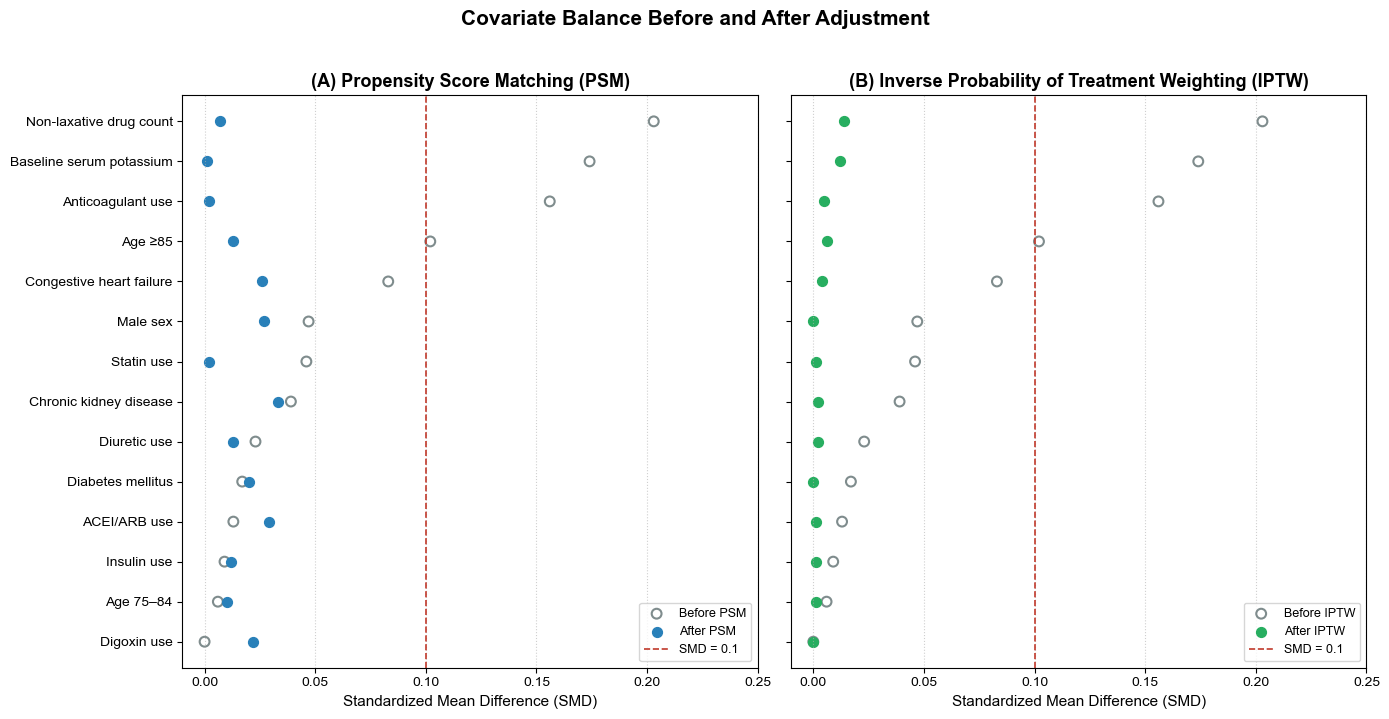

✅ 合并版 Love Plot 生成完毕！


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

# 设置 Arial 字体
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

# ========== 1. 准备数据 ==========
name_map = {
    'gender_male': 'Male sex',
    'age_75_84': 'Age 75–84',
    'age_85plus': 'Age ≥85',
    'baseline_k': 'Baseline serum potassium',
    'drug_count_no_laxatives': 'Non-laxative drug count',
    'chf': 'Congestive heart failure',
    'ckd': 'Chronic kidney disease',
    'dm': 'Diabetes mellitus',
    'diuretic': 'Diuretic use',
    'acei_arb': 'ACEI/ARB use',
    'digoxin': 'Digoxin use',
    'insulin': 'Insulin use',
    'statin': 'Statin use',
    'anticoagulant': 'Anticoagulant use'
}

# PSM 数据
psm_data = {
    'Variable': ['gender_male', 'age_75_84', 'age_85plus', 'baseline_k', 'drug_count_no_laxatives', 'chf', 'ckd', 'dm', 'diuretic', 'acei_arb', 'digoxin', 'insulin', 'statin', 'anticoagulant'],
    'SMD_before': [0.047, 0.006, 0.102, 0.174, 0.203, 0.083, 0.039, 0.017, 0.023, 0.013, 0.0, 0.009, 0.046, 0.156],
    'SMD_after': [0.027, 0.01, 0.013, 0.001, 0.007, 0.026, 0.033, 0.02, 0.013, 0.029, 0.022, 0.012, 0.002, 0.002]
}
df_psm = pd.DataFrame(psm_data)

# IPTW 数据
iptw_data = {
    'Variable': ['gender_male', 'age_75_84', 'age_85plus', 'baseline_k', 'drug_count_no_laxatives', 'chf', 'ckd', 'dm', 'diuretic', 'acei_arb', 'digoxin', 'insulin', 'statin', 'anticoagulant'],
    'SMD_before': [0.047, 0.006, 0.102, 0.174, 0.203, 0.083, 0.039, 0.017, 0.023, 0.013, 0.0, 0.009, 0.046, 0.156],
    'SMD_after': [0, 0.001, 0.006, 0.012, 0.014, 0.004, 0.002, 0, 0.002, 0.001, 0, 0.001, 0.001, 0.005]
}
df_iptw = pd.DataFrame(iptw_data)

# 映射并排序
for df in [df_psm, df_iptw]:
    df['Variable'] = df['Variable'].map(name_map)
    df.sort_values('SMD_before', ascending=True, inplace=True)
    df.reset_index(drop=True, inplace=True)

# ========== 2. 开始画图 ==========
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)

# --- Panel A: PSM ---
y = np.arange(len(df_psm))
axes[0].scatter(df_psm['SMD_before'], y, color='#7F8C8D', marker='o', s=50, label='Before PSM', facecolors='none', edgecolors='#7F8C8D', linewidth=1.5)
axes[0].scatter(df_psm['SMD_after'], y, color='#2980B9', marker='o', s=50, label='After PSM')
axes[0].axvline(x=0.1, color='#C0392B', linestyle='--', linewidth=1.2, label='SMD = 0.1')
axes[0].set_title('(A) Propensity Score Matching (PSM)', fontsize=13, fontweight='bold')
axes[0].set_yticks(y)
axes[0].set_yticklabels(df_psm['Variable'], fontsize=10)
axes[0].set_xlabel('Standardized Mean Difference (SMD)', fontsize=11)
axes[0].legend(loc='lower right', frameon=True, fontsize=9)
axes[0].grid(axis='x', linestyle=':', alpha=0.6)
axes[0].set_xlim(-0.01, 0.25)

# --- Panel B: IPTW ---
axes[1].scatter(df_iptw['SMD_before'], y, color='#7F8C8D', marker='o', s=50, label='Before IPTW', facecolors='none', edgecolors='#7F8C8D', linewidth=1.5)
axes[1].scatter(df_iptw['SMD_after'], y, color='#27AE60', marker='o', s=50, label='After IPTW')
axes[1].axvline(x=0.1, color='#C0392B', linestyle='--', linewidth=1.2, label='SMD = 0.1')
axes[1].set_title('(B) Inverse Probability of Treatment Weighting (IPTW)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Standardized Mean Difference (SMD)', fontsize=11)
axes[1].legend(loc='lower right', frameon=True, fontsize=9)
axes[1].grid(axis='x', linestyle=':', alpha=0.6)
axes[1].set_xlim(-0.01, 0.25)

plt.suptitle('Covariate Balance Before and After Adjustment', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Figure_S1_Balance_Plots.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ 合并版 Love Plot 生成完毕！")